# Análise de Tuberculose — Ilhéus e Itabuna, 2014-2024

**Notebook consolidado.** Resume os resultados dos notebooks 09 a 14 e responde à pergunta de pesquisa.
Ele não recalcula a base: lê as tabelas que os notebooks anteriores salvaram em `data/processed` e as figuras
de `reports/figuras`. Para atualizar, rode antes os notebooks 09 a 14 em ordem.

**Pergunta de pesquisa.** Quais fatores sociodemográficos, clínicos e operacionais estão associados ao desfecho
desfavorável do tratamento da tuberculose (abandono ou óbito) em Ilhéus e Itabuna, e quão distantes as duas
cidades estão das metas do Ministério da Saúde e da OMS?

1. [Dados e métodos](#1)
2. [Quanto adoece: incidência por 100 mil](#2)
3. [Indicadores do programa x metas](#3)
4. [Ilhéus x Itabuna: onde as cidades diferem](#4)
5. [Fatores associados ao desfecho desfavorável](#5)
6. [Tempo até o tratamento e transmissão estimada](#6)
7. [Pandemia e a queda de 2023](#7)
8. [Contexto regional: 10 cidades, Bahia, IDH e pacientes de fora](#8)
9. [Comparação com números publicados](#9)
10. [Respostas às perguntas da reunião](#10)
11. [Limitações](#11)
12. [Conclusão geral e recomendações](#12)

In [1]:
import sys
from pathlib import Path
sys.path.append(str(Path('..', 'src').resolve()))

import pandas as pd
from IPython.display import Image, display
import tb_utils as tb

pd.set_option('display.max_columns', 30)
pd.set_option('display.width', 160)
P = tb.PROCESSED
F = tb.FIGURAS

def fig(nome, largura=900):
    display(Image(filename=str(F / f'{nome}.png'), width=largura))

## 1. Dados e métodos <a id='1'></a>

- **Fonte:** microdados do SINAN Tuberculose (DATASUS), arquivos TUBEBR14 a TUBEBR24, Brasil inteiro.
- **População:** Censos 2010 e 2022 do IBGE, com interpolação geométrica entre eles e a mesma taxa de crescimento
  para 2023-2024. As estimativas anuais antigas do IBGE superestimavam a população de Itabuna (214 mil contra
  187 mil no Censo 2022), o que baixava a incidência.
- **Unidade de análise:** caso por município de **residência**. Incidência = casos novos por 100 mil habitantes.
- **Desfechos:** coorte de casos novos, como no Ministério da Saúde (sem mudança de diagnóstico).
- **Estatística:** IC de Wilson e de Poisson; Fisher com correção de Bonferroni; regressão logística;
  Poisson para casos esperados; Spearman para IDH e densidade.
- **Notebooks:** 09 base corrigida · 10 incidência e indicadores · 11 Ilhéus x Itabuna, tempo e transmissão ·
  12 regressão · 13 pandemia e 2023 · 14 cidades, Bahia e atendimento.

In [2]:
base = tb.carrega_base()
ii = tb.residentes_ii(base)
resumo = ii.groupby('cidade').agg(notificacoes=('caso_novo', 'size'), casos_novos=('caso_novo', 'sum'),
                                  retratamentos=('retratamento', 'sum'))
resumo.loc['Total'] = resumo.sum()
resumo

,notificacoes,casos_novos,retratamentos
cidade,,,
Ilhéus,1489,1161,243
Itabuna,1762,1482,246
Total,3251,2643,489


## 2. Quanto adoece: incidência por 100 mil <a id='2'></a>

In [3]:
inc = pd.read_csv(P / 'incidencia_anual.csv')
inc.pivot_table(index='ano', columns='local', values='taxa').round(1)

local,Bahia,Brasil,Ilhéus,Itabuna
ano,,,,
2014,33.2,35.7,52.6,63.5
2015,30.6,35.3,53.3,53.8
2016,30.1,35.4,61.2,66.0
2017,30.8,36.8,55.3,72.7
2018,31.9,38.4,61.5,64.4
2019,32.0,38.7,75.5,79.0
2020,25.8,33.9,37.9,77.5
2021,28.3,35.5,59.2,79.7
2022,30.3,39.3,64.9,85.7


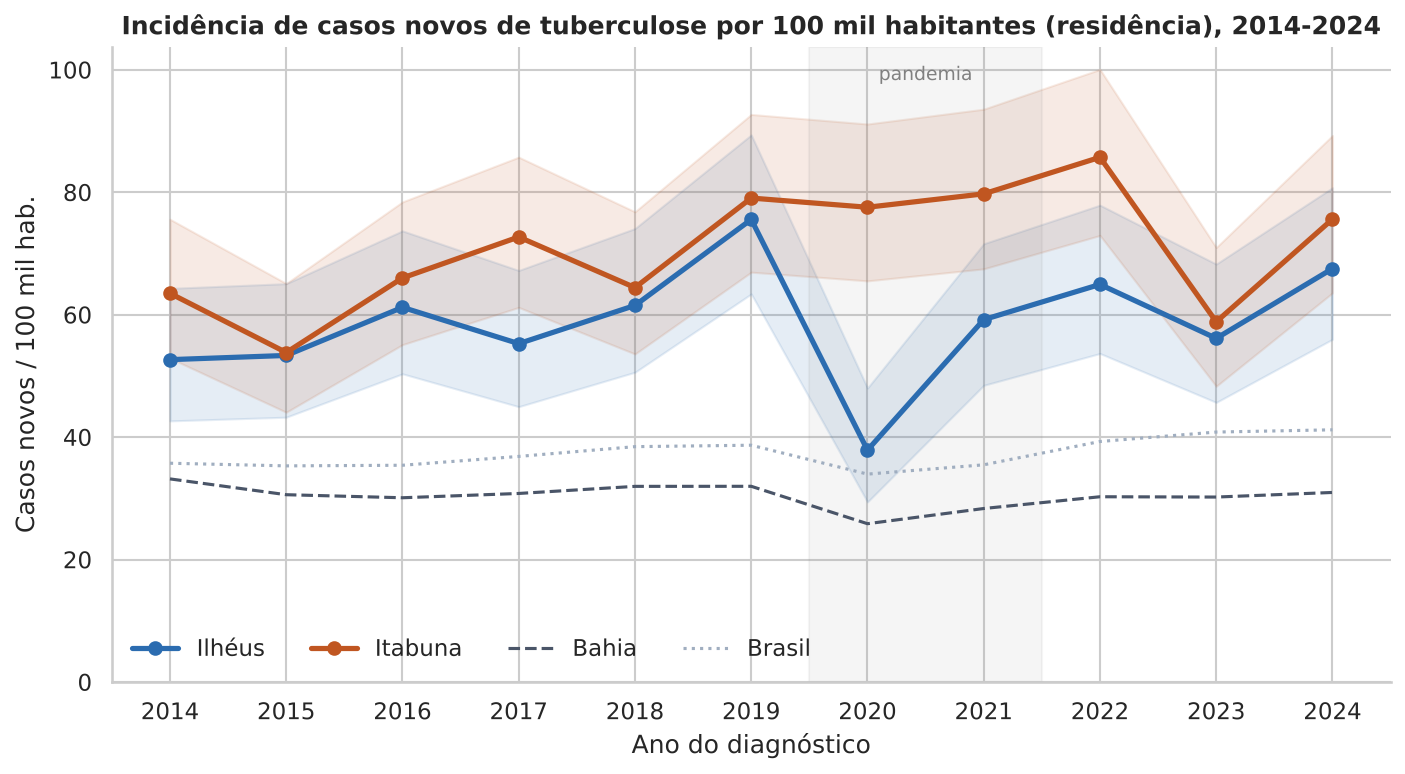

In [4]:
fig('10_incidencia_anual')

**Conclusão.** Itabuna tem a maior incidência média da Bahia entre os 417 municípios (70,5 por 100 mil) e Ilhéus
está em 5º lugar (58,6), ambas cerca de duas vezes a média estadual (30,4). A razão Itabuna/Ilhéus é 1,20
(IC 95% 1,11–1,30).

## 3. Indicadores do programa x metas <a id='3'></a>

In [5]:
prog = pd.read_csv(P / 'indicadores_programa_ano.csv')
cols = ['cura (%)', 'abandono (%)', 'óbito por TB (%)', 'testagem HIV (%)', 'contatos examinados (%)',
        'cultura realizada, pulmonares (%)', 'TDO preenchido (%)']
media = prog.groupby('cidade')[cols].mean().T
media['meta'] = ['≥ 85', '< 5', '—', '100', '≥ 70', '100 (retratamento)', '—']
media.round(1)

cidade,Ilhéus,Itabuna,meta
cura (%),78.8,74.6,≥ 85
abandono (%),11.6,13.1,< 5
óbito por TB (%),2.2,5.6,—
testagem HIV (%),62.5,70.2,100
contatos examinados (%),48.3,32.5,≥ 70
"cultura realizada, pulmonares (%)",41.8,15.8,100 (retratamento)
TDO preenchido (%),91.6,47.3,—


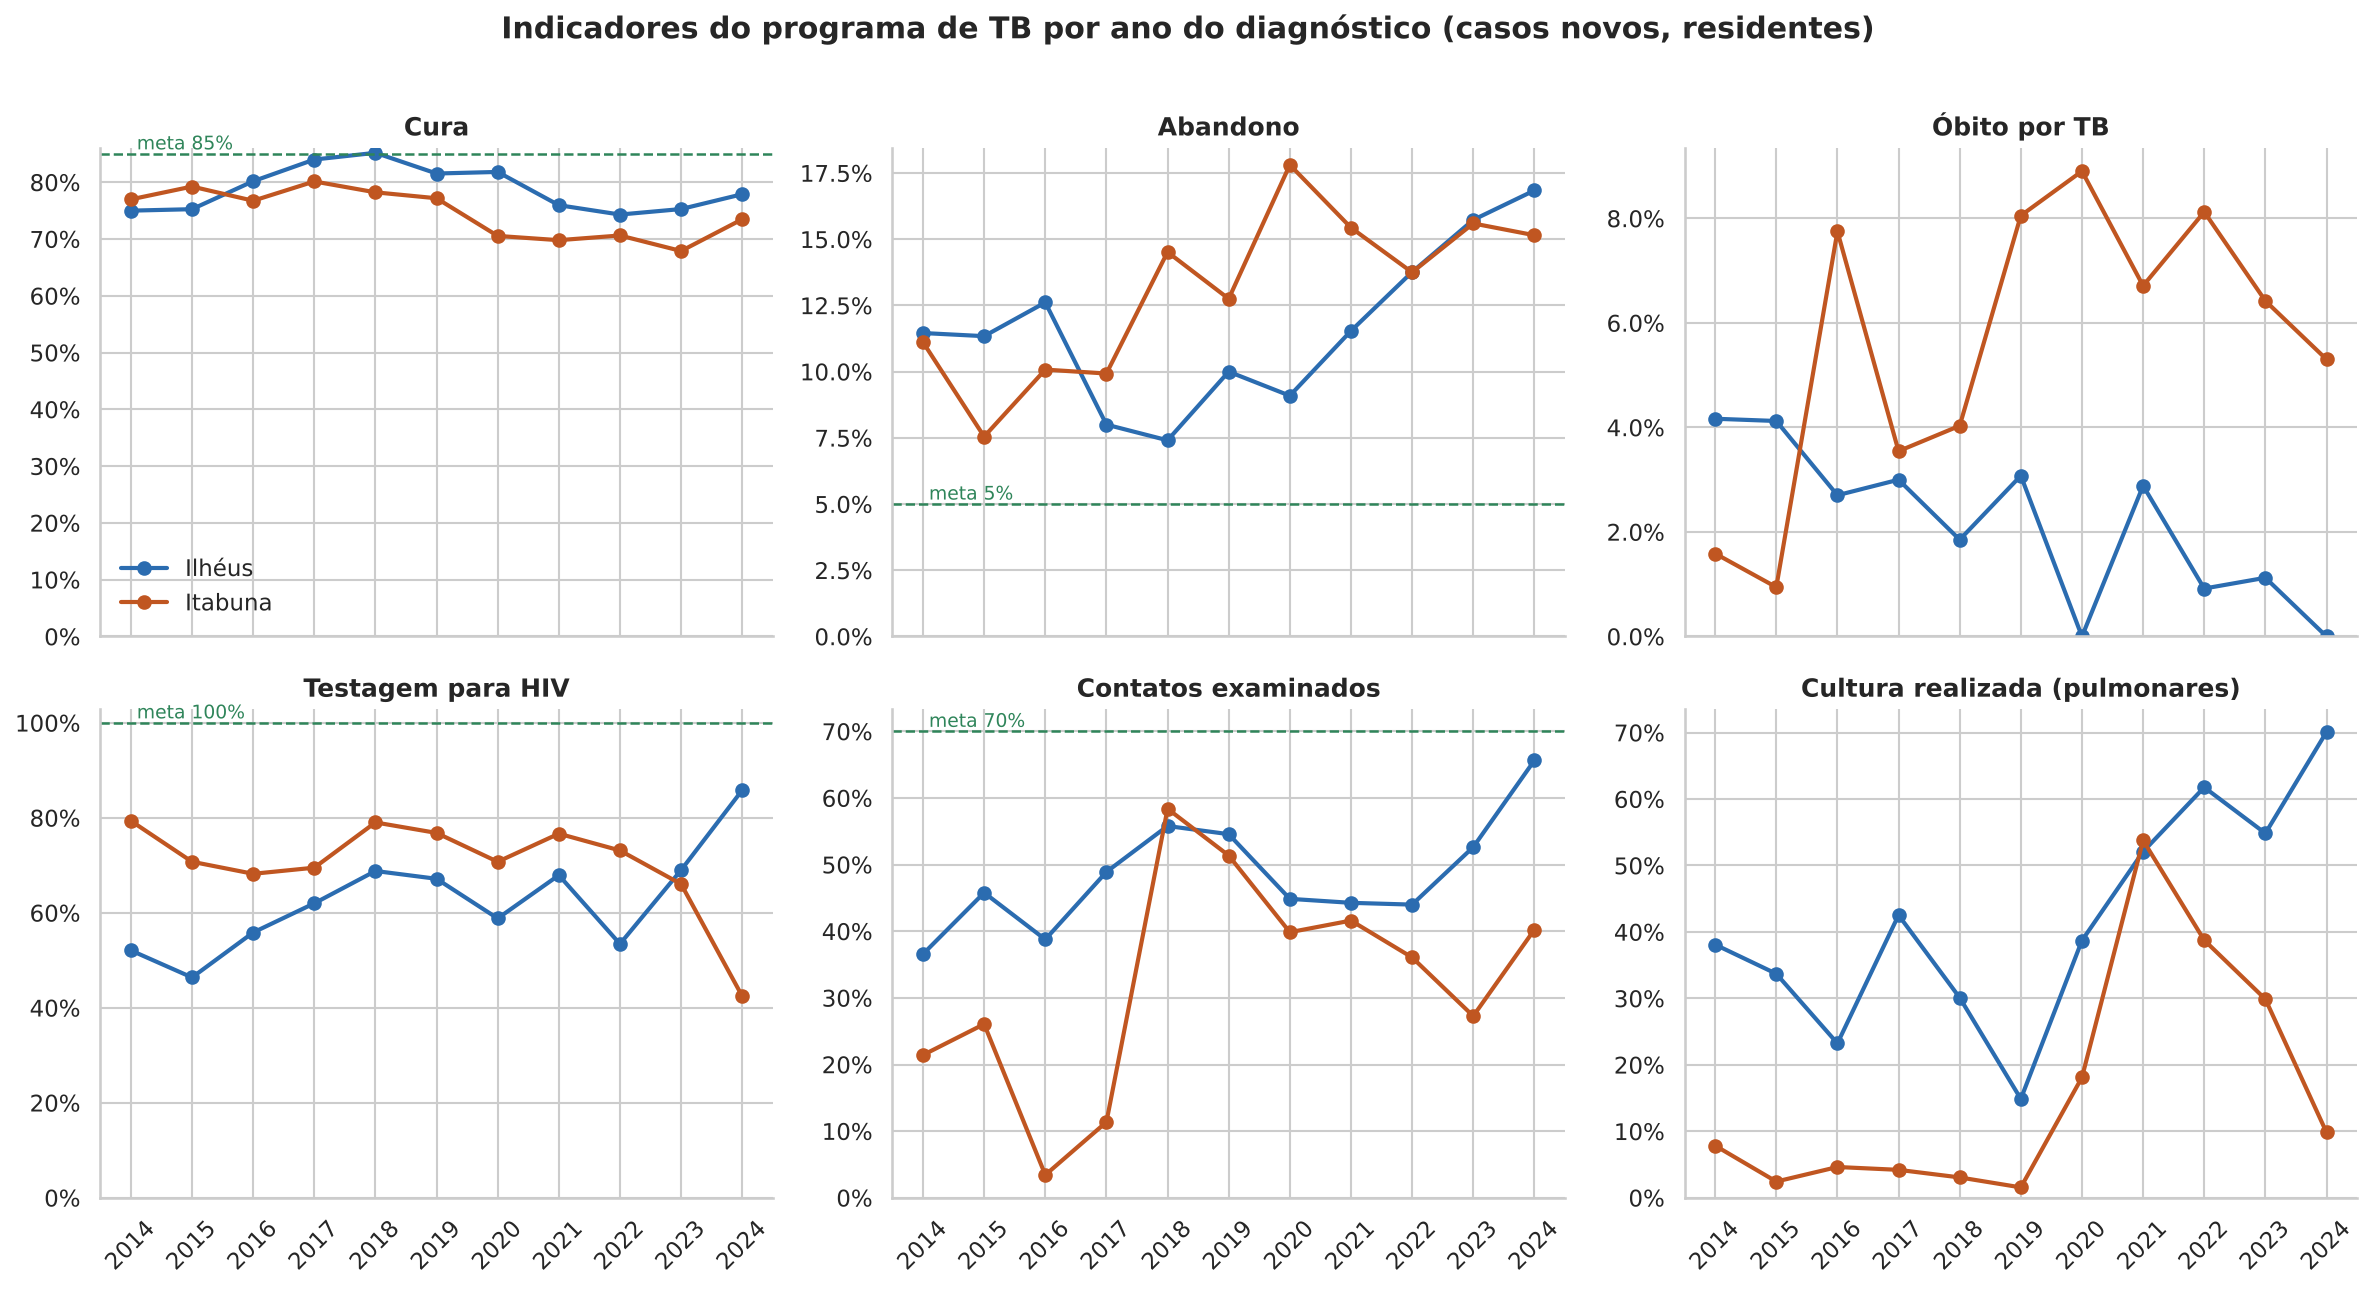

In [6]:
fig('10_indicadores_programa')

**Conclusão.** Nenhuma das duas cidades atinge a meta de cura (85%) em nenhum ano, e o abandono fica 2 a 3 vezes
acima do limite de 5%. A testagem para HIV (63% em Ilhéus, 70% em Itabuna) e o exame de contatos (49% e 33%)
também estão abaixo das metas. O TDO quase não aparece registrado como realizado, e em Itabuna o campo ficou vazio
de 2016 a 2020: o dado não permite medir o TDO, o que já é um achado sobre o serviço.

## 4. Ilhéus x Itabuna: onde as cidades diferem <a id='4'></a>

In [7]:
testes = pd.read_csv(P / 'testes_ilheus_itabuna.csv')
testes[testes['significativo (5%)'].eq('sim')].round(3)

,indicador,n Itabuna,% Itabuna,n Ilhéus,% Ilhéus,OR,IC95% inf,IC95% sup,p (Fisher),p ajustado,significativo (5%)
2,Óbito por TB,1471,5.778,1105,2.262,2.649,1.684,4.167,0.0,0.000,sim
4,Forma extrapulmonar,1762,15.834,1484,9.838,1.724,1.393,2.134,0.0,0.000,sim
6,Cultura realizada (pulmonares),1221,16.380,1033,41.723,0.274,0.225,0.333,0.0,0.000,sim
7,Testagem para HIV,1482,70.310,1157,63.094,1.385,1.176,1.631,0.0,0.002,sim
9,Alcoolismo,1488,14.583,1338,26.756,0.467,0.387,0.564,0.0,0.000,sim
10,Drogas ilícitas,1404,12.464,1237,18.189,0.640,0.517,0.794,0.0,0.001,sim
11,Tabagismo,1409,25.337,1292,34.056,0.657,0.556,0.776,0.0,0.000,sim
13,Situação de rua,1510,1.656,1385,4.188,0.385,0.240,0.619,0.0,0.001,sim
14,Privado de liberdade,1619,19.086,1384,3.107,7.356,5.299,10.211,0.0,0.000,sim
15,Beneficiário de programa social,1339,6.572,1104,19.475,0.291,0.224,0.378,0.0,0.000,sim


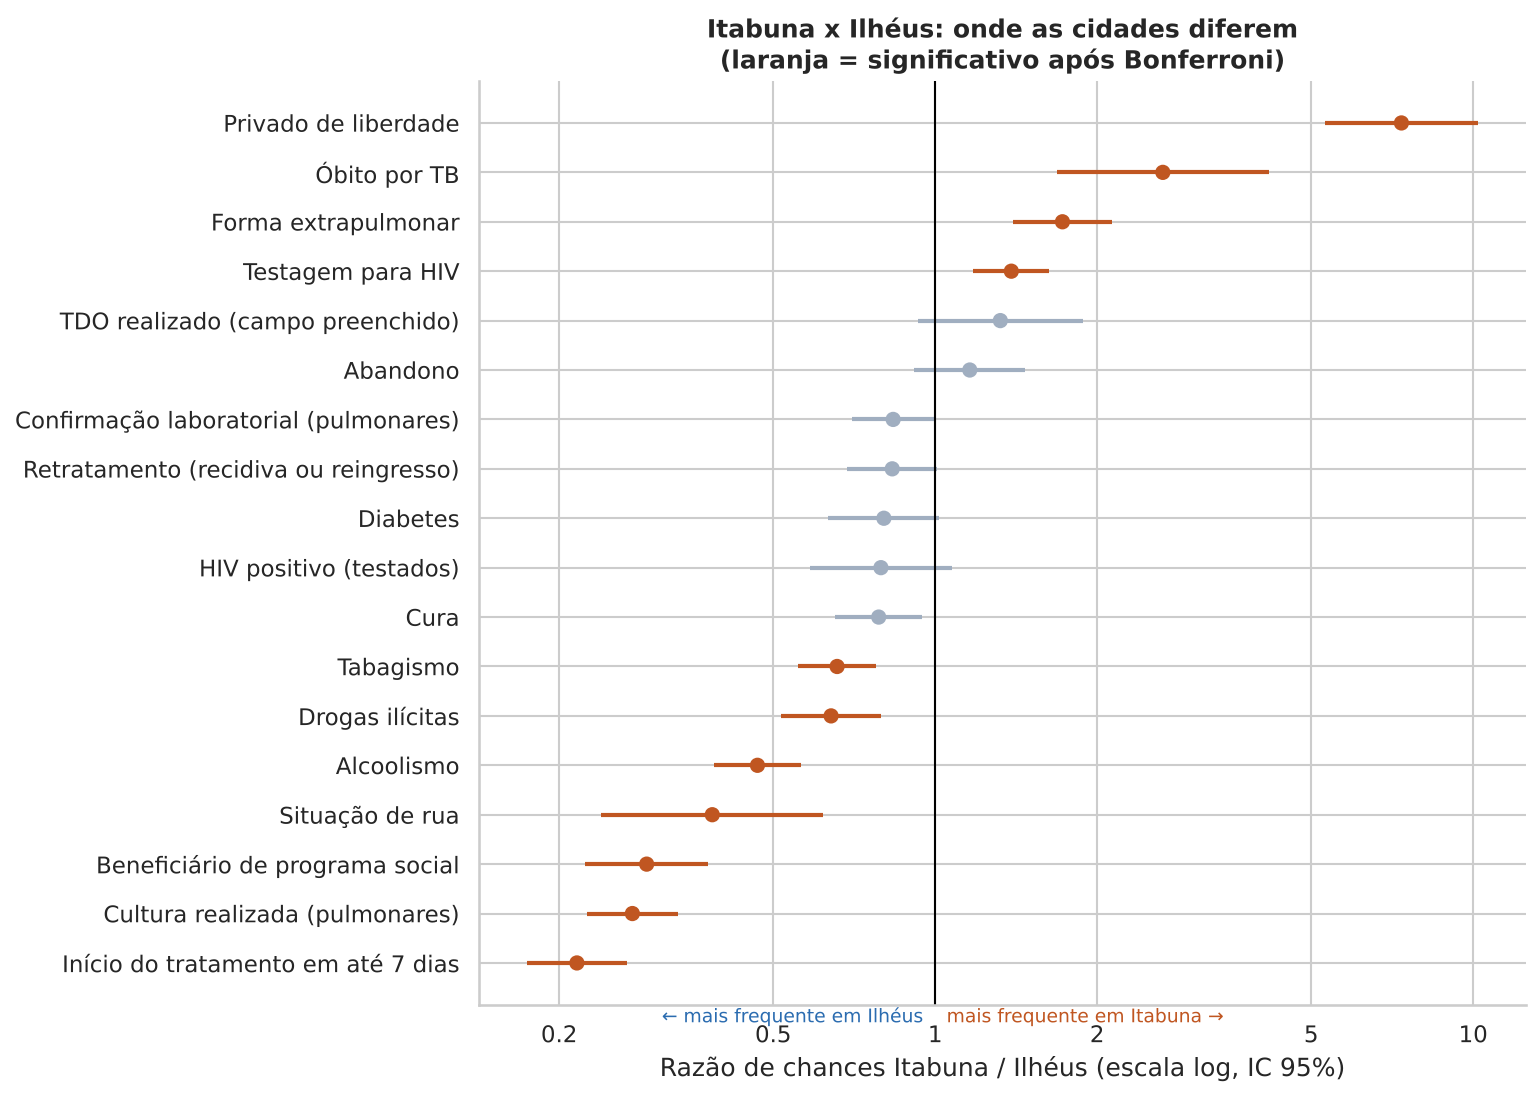

In [8]:
fig('11_forest_ilheus_itabuna')

**Conclusão.** Itabuna morre mais de TB (5,8% x 2,3%; OR 2,65), tem mais casos extrapulmonares, menos cultura,
mais pessoas privadas de liberdade (19% dos casos novos, ligado ao presídio da cidade) e mais demora para começar
o tratamento. Ilhéus registra muito mais alcoolismo, drogas, tabagismo e situação de rua. Cura e abandono, sozinhos,
não diferem depois da correção de Bonferroni.

## 5. Fatores associados ao desfecho desfavorável <a id='5'></a>

In [9]:
reg = pd.read_csv(P / 'regressao_desfecho_desfavoravel.csv')
reg[reg['p ajustado'] < 0.05].sort_values('OR ajustado', ascending=False)[
    ['variável', 'categoria', 'ref.', 'OR bruto', 'OR ajustado', 'IC95% inf ajustado', 'IC95% sup ajustado', 'p ajustado']].round(3)

,variável,categoria,ref.,OR bruto,OR ajustado,IC95% inf ajustado,IC95% sup ajustado,p ajustado
18,Situação de rua,Sim,Não,5.598,3.890,1.195,12.661,0.024
11,HIV,Não testado / em andamento,Negativo,1.959,2.203,1.650,2.941,0.000
13,Alcoolismo,Sim,Não,2.813,2.087,1.432,3.043,0.000
0,Cidade,Itabuna,Ilhéus,1.454,2.051,1.510,2.784,0.000
12,HIV,Positivo,Negativo,2.452,1.966,1.100,3.512,0.022
14,Drogas ilícitas,Sim,Não,2.777,1.684,1.108,2.561,0.015
15,Tabagismo,Sim,Não,2.450,1.650,1.170,2.327,0.004
21,Período,2020-2021,2014-2019,1.481,1.613,1.132,2.298,0.008
22,Período,2022-2024,2014-2019,1.423,1.430,1.034,1.977,0.031


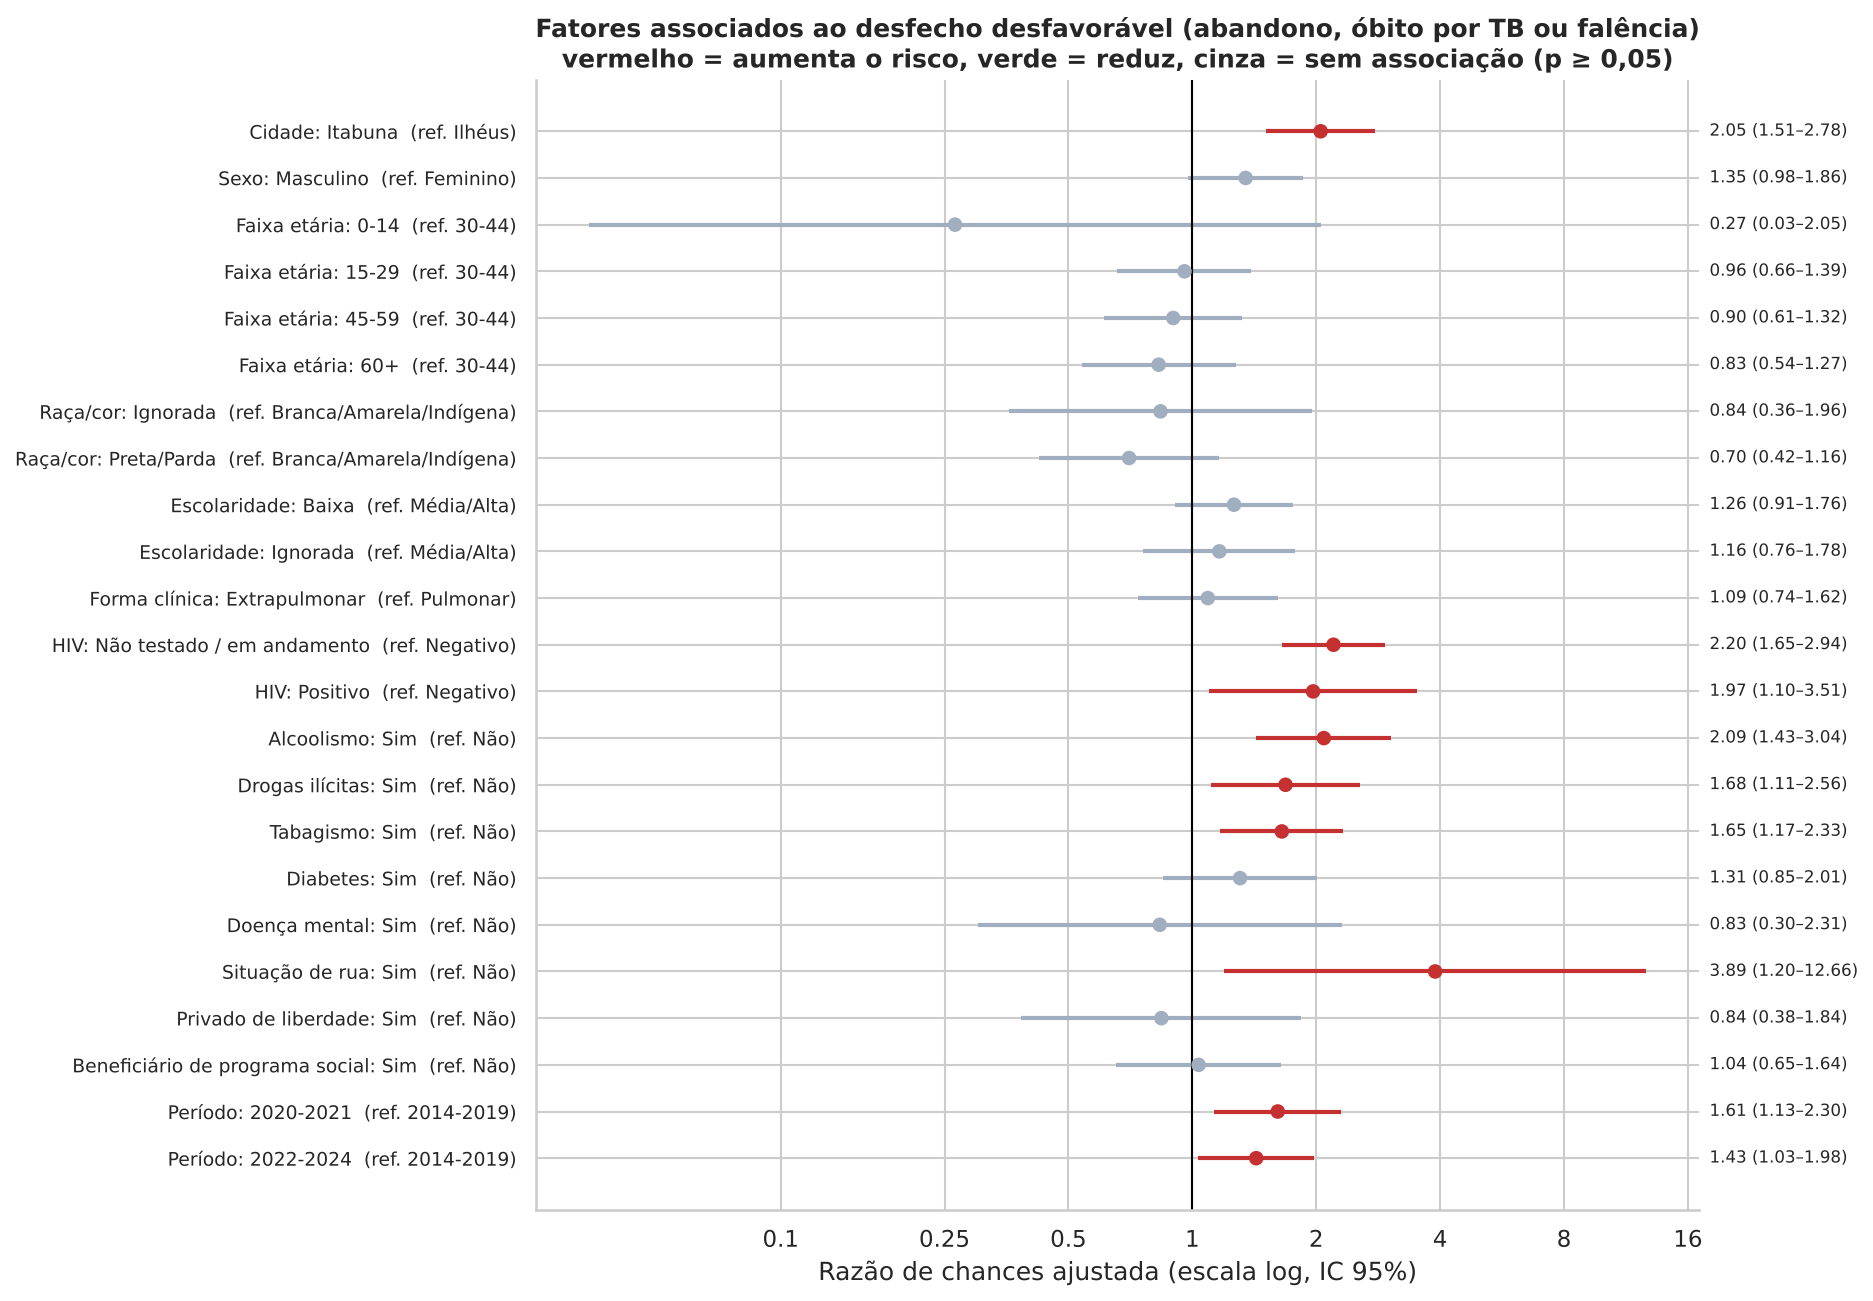

In [10]:
fig('12_forest_desfavoravel')

**Conclusão.** Situação de rua (OR 3,9), não ter feito o teste de HIV (OR 2,2), alcoolismo (OR 2,1), HIV positivo
(OR 2,0), drogas (OR 1,7), tabagismo (OR 1,7) e os anos da pandemia e pós-pandemia aumentam a chance de abandono ou
óbito. **Morar em Itabuna dobra essa chance (OR 2,05) mesmo com o perfil dos pacientes ajustado**, o que aponta para
diferenças no serviço. A escolaridade perde o efeito depois do ajuste. O modelo tem AUC 0,72.

## 6. Tempo até o tratamento e transmissão estimada <a id='6'></a>

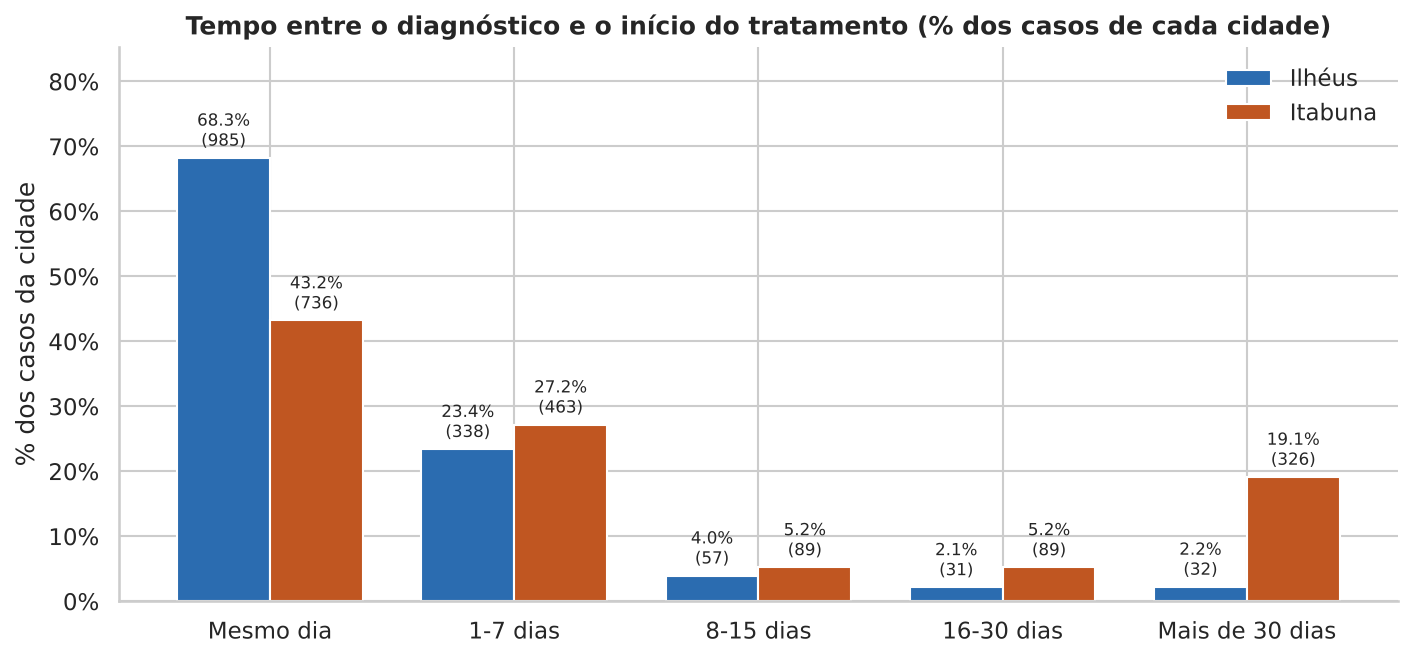

In [11]:
fig('11_espera_percentual')

In [12]:
trans = pd.read_csv(P / 'transmissao_estimada.csv')
trans[trans['cenário'].eq('sem janela pré-diagnóstico')].round(0)

,cidade,taxa,cenário,bacilíferos,dias sem tratamento após diagnóstico,infecções estimadas,casos futuros (5%),casos futuros (10%),infecções evitáveis com início em até 7 dias
0,Ilhéus,baixa (10/ano),sem janela pré-diagnóstico,928,3529.0,97.0,5.0,10.0,57.0
3,Ilhéus,alta (15/ano),sem janela pré-diagnóstico,928,3529.0,145.0,7.0,15.0,86.0
6,Itabuna,baixa (10/ano),sem janela pré-diagnóstico,949,20492.0,561.0,28.0,56.0,483.0
9,Itabuna,alta (15/ano),sem janela pré-diagnóstico,949,20492.0,842.0,42.0,84.0,724.0


**Conclusão.** Em Ilhéus a mediana entre diagnóstico e início do tratamento é zero dias; em Itabuna é 1 dia, mas
1 em cada 4 casos espera mais de 15 dias e 1 em 10 mais de 75 dias. Em 2014-2015 mais de 40% dos casos de
Itabuna esperavam mais de 30 dias. Contando só o tempo após o diagnóstico, os bacilíferos de Itabuna teriam
gerado de 560 a 840 infecções, das quais 480 a 720 seriam evitáveis com início em até 7 dias. É uma estimativa por
modelo (10 a 15 infecções por ano de doença ativa, OMS), não uma contagem.

## 7. Pandemia e a queda de 2023 <a id='7'></a>

In [13]:
esp = pd.read_csv(P / 'esperado_observado_pandemia.csv')
esp[esp['ano'] >= 2019].round(1)

,cidade,ano,observado,esperado,esperado_inf,esperado_sup,diferença,diferença %,fora do intervalo
5,Ilhéus,2019,136,126.9,101.0,156.0,9.1,7.2,False
6,Ilhéus,2020,68,135.1,106.0,168.0,-67.1,-49.7,True
7,Ilhéus,2021,106,143.8,109.0,184.0,-37.8,-26.3,True
8,Ilhéus,2022,116,153.2,110.0,202.0,-37.2,-24.3,False
9,Ilhéus,2023,100,163.3,114.0,224.0,-63.3,-38.8,True
10,Ilhéus,2024,120,174.2,118.0,248.0,-54.2,-31.1,False
16,Itabuna,2019,151,145.0,115.0,176.0,6.0,4.1,False
17,Itabuna,2020,147,151.5,120.0,185.0,-4.5,-3.0,False
18,Itabuna,2021,150,158.3,121.0,200.0,-8.3,-5.2,False
19,Itabuna,2022,160,165.5,123.0,212.0,-5.5,-3.3,False


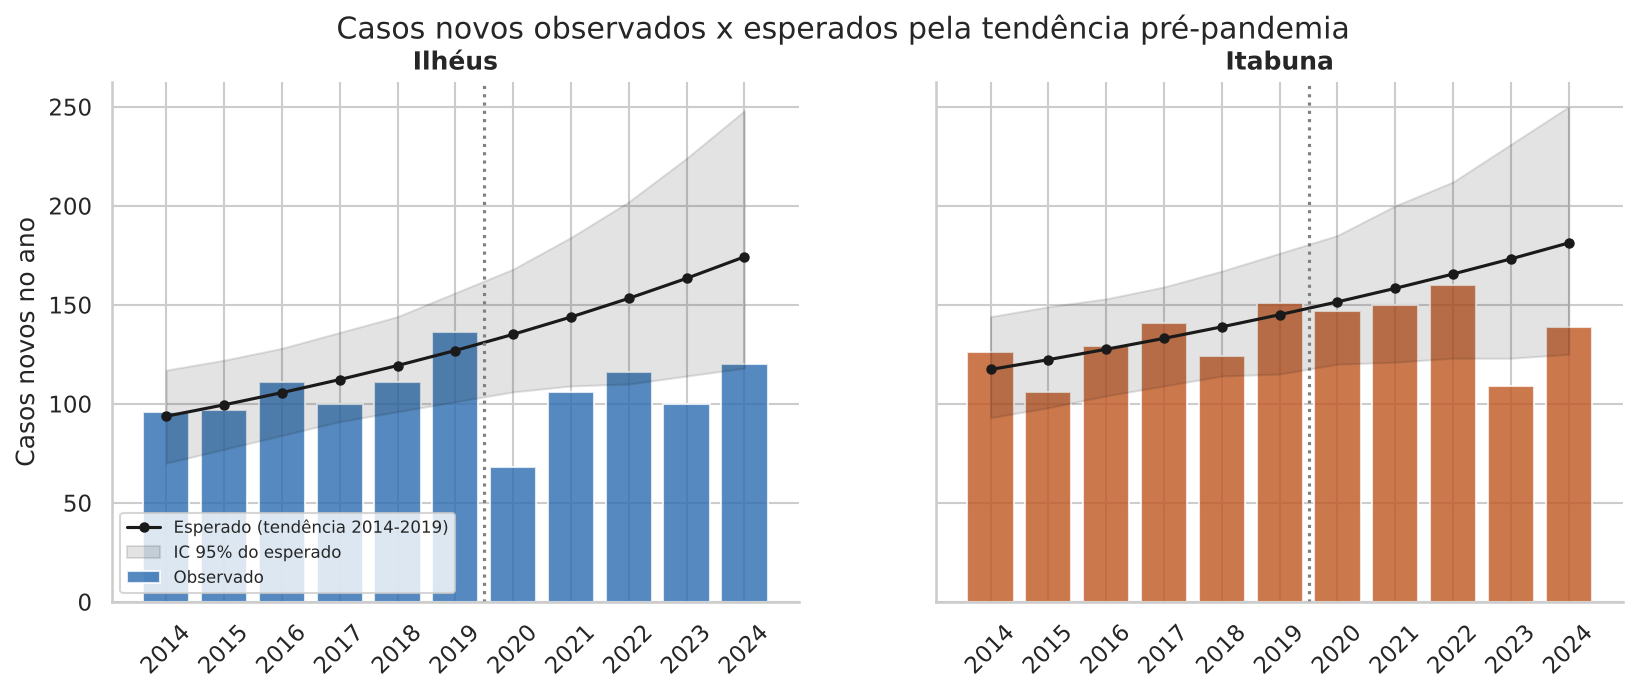

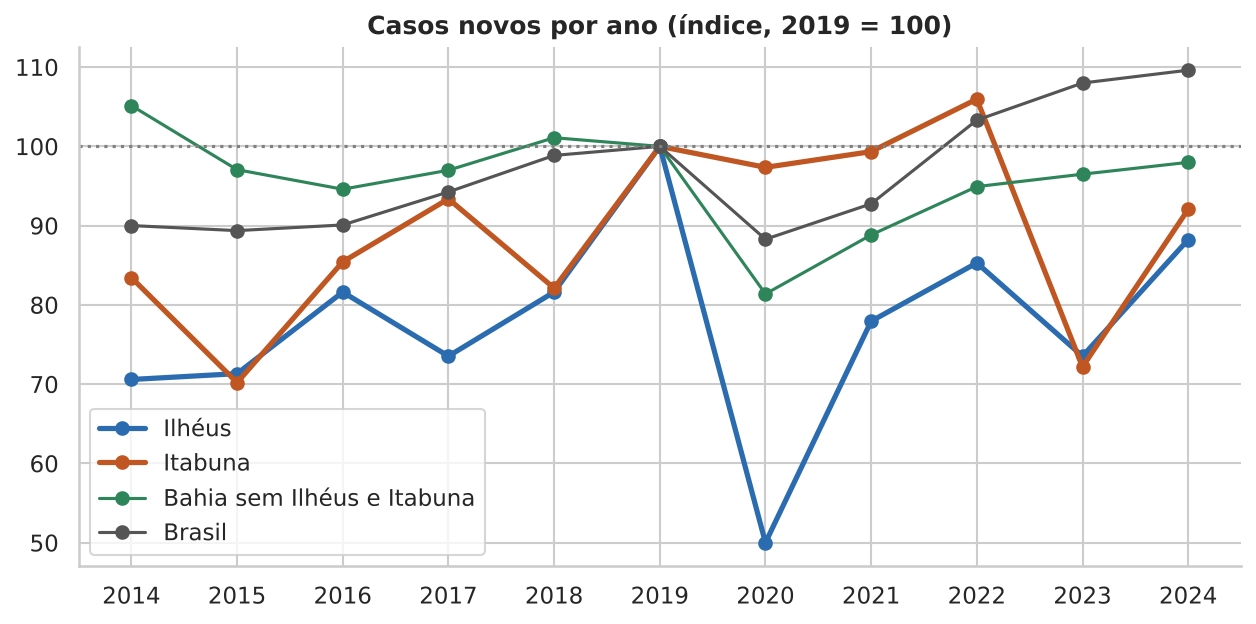

In [14]:
fig('13_esperado_observado')
fig('13_indice_2019', 750)

**Conclusão.** Em Ilhéus faltaram cerca de 105 diagnósticos em 2020-2021 (−38% do esperado). Itabuna manteve os
diagnósticos, mas o abandono subiu para 16,6% e o óbito por TB para 7,8%. A queda de 2023 é local: Itabuna caiu 32%
e Ilhéus 14%, enquanto a Bahia e o Brasil subiram. Em Itabuna a queda foi na população geral atendida nas UBS, ao
longo do ano todo, e não é atraso de digitação.

## 8. Contexto regional <a id='8'></a>

In [15]:
pd.read_csv(P / 'incidencia_10_cidades.csv').round(1)

,cidade,grupo,casos novos 2014-2024,taxa média /100 mil,IC inf,IC sup
0,Recife,Litoral,16069,97.3,95.8,98.8
1,Rio de Janeiro,Litoral,65877,96.0,95.3,96.7
2,Itabuna,Interior,1482,70.5,67.0,74.2
3,Salvador,Litoral,16131,59.1,58.2,60.0
4,Ilhéus,Litoral,1161,58.6,55.3,62.1
5,São Paulo,Interior,68503,54.6,54.2,55.0
6,Aracaju,Litoral,2587,39.5,38.0,41.1
7,Feira de Santana,Interior,1895,28.7,27.4,30.0
8,Curitiba,Interior,3547,18.2,17.6,18.8
9,Vitória da Conquista,Interior,677,17.4,16.1,18.7


In [16]:
pd.read_csv(P / 'indicadores_10_cidades.csv', index_col=0).round(1)

,coorte (n),cura %,abandono %,óbito TB %,testagem HIV %,HIV+ %,pulmonar %,alcoolismo %,situação de rua %,privado de liberdade %
cidade,,,,,,,,,,
Ilhéus,1105,78.8,11.6,2.3,63.1,7.4,89.0,23.8,1.8,3.3
Itabuna,1471,74.5,13.2,5.8,70.3,6.7,82.4,12.7,1.3,17.3
Vitória da Conquista,639,79.8,3.6,6.3,87.4,8.9,76.7,31.4,2.9,2.4
Feira de Santana,1881,79.6,8.3,5.5,72.6,8.7,82.1,17.6,1.3,10.9
Salvador,14891,66.0,12.3,3.1,71.7,9.5,86.0,19.7,2.6,3.7
Recife,15856,65.1,14.7,3.6,73.6,11.7,86.4,21.5,3.6,14.2
Aracaju,2511,69.2,17.4,3.4,76.4,7.0,83.6,21.3,4.7,5.1
Rio de Janeiro,63045,71.5,14.6,3.1,87.5,9.0,89.5,12.6,3.8,14.0
São Paulo,66828,74.5,15.1,3.6,91.7,9.5,83.4,18.9,7.8,3.6


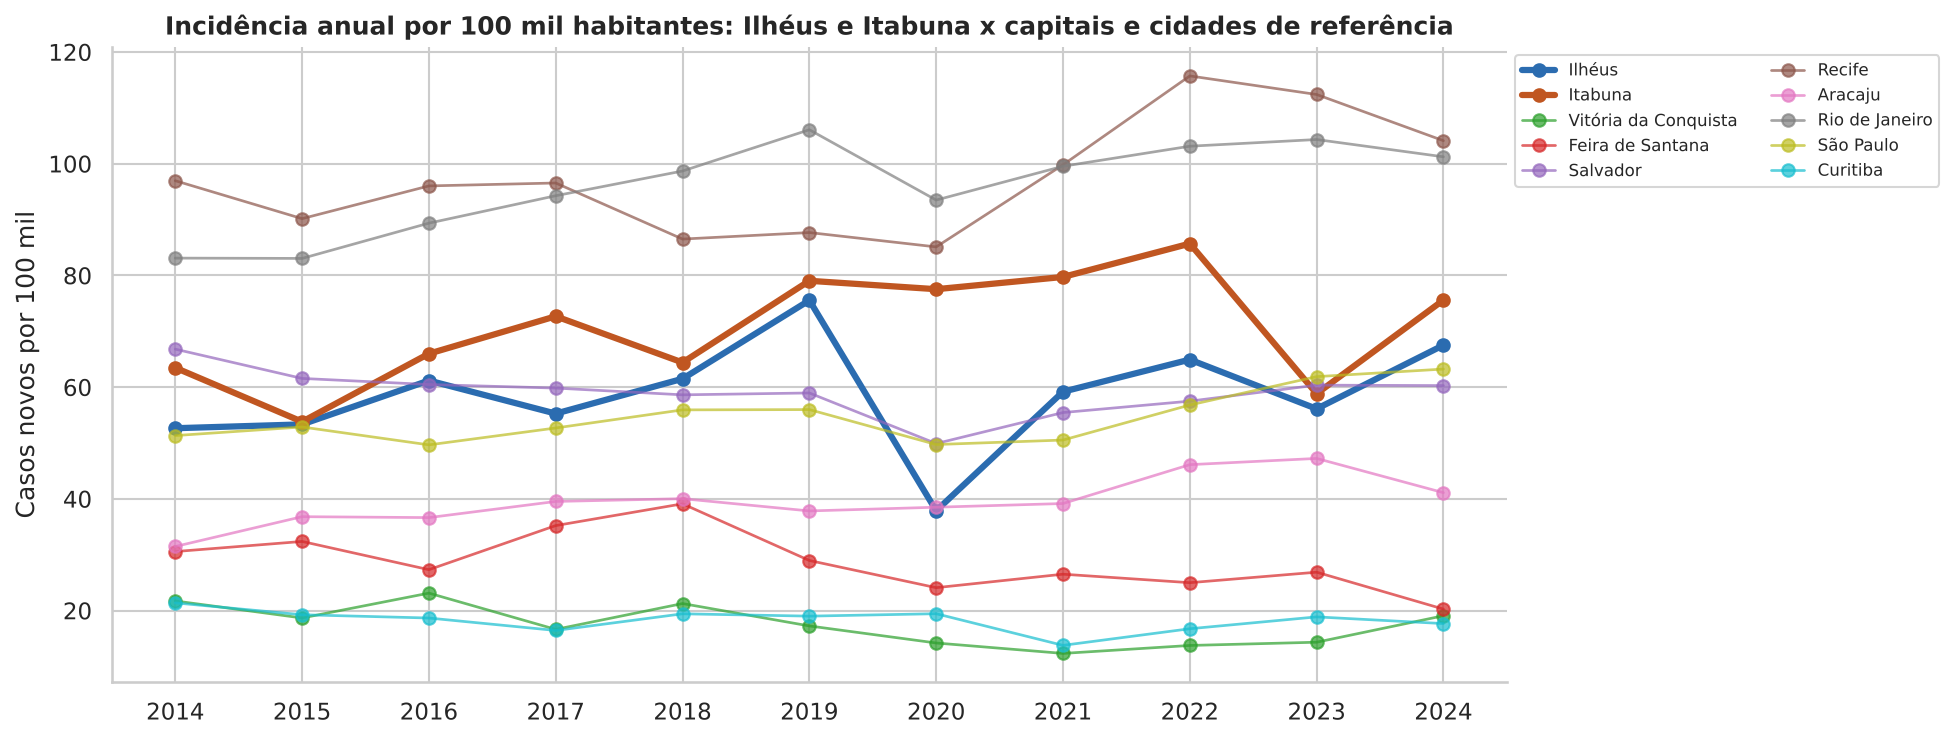

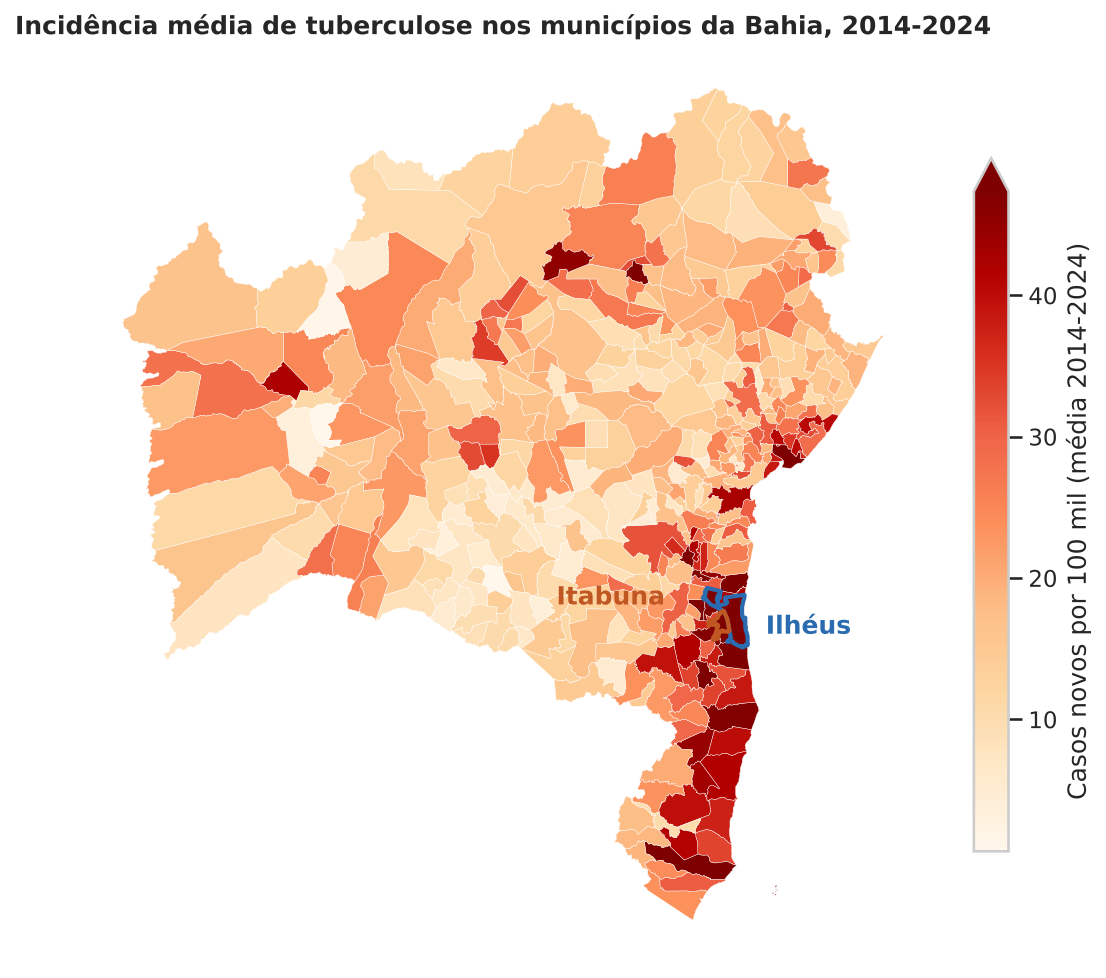

In [17]:
fig('14_incidencia_anual_10_cidades')
fig('14_mapa_bahia', 650)

**Conclusão.** Normalizadas por 100 mil habitantes, Itabuna e Ilhéus ficam no nível de Salvador e São Paulo e
abaixo apenas de Recife e Rio de Janeiro. O mapa mostra que o sul e extremo sul da Bahia formam a faixa de maior
incidência do estado. IDH e densidade se correlacionam positivamente com a incidência (rho ≈ 0,4 nos municípios
com 20 mil habitantes ou mais), o que reflete urbanização e capacidade de diagnóstico, e não proteção pela pobreza.
Ilhéus recebe 10,6% de pacientes de outros municípios (sobretudo Uruçuca, Itacaré e Una) e Itabuna 3,8%; pela
notificação, a incidência de Ilhéus subiria 10%. Os moradores de Ilhéus são atendidos quase todos na própria
cidade (98%), 78% em UBS e 12% em hospital geral.

## 9. Comparação com números publicados <a id='9'></a>

A tabela completa, com links para as fontes, está no notebook 14, seção 6.

- **Bahia e Brasil:** as incidências calculadas aqui batem com os boletins da SESAB (2014-2022) e do Ministério da
  Saúde (Brasil 2024: 40,4 publicado x 41,2 aqui). Para 2023-2024 o boletim de 2026 dá valores maiores, pela
  extração mais recente.
- **Macrorregião Sul:** incidência de 42 a 46 por 100 mil em 2023-2024 (SESAB). Ilhéus e Itabuna ficam acima dela.
- **Estudos locais:** o TCC de Medeiros (2023) sobre TB pulmonar em Ilhéus 2018-2022 encontra 661 casos, 12,1% de
  abandono, 2,1% de óbito por TB e 7,3% de HIV positivo, muito próximo daqui (675; 13,5%; 2,1%; 7,3%).
  Rodrigues et al. (2019) acharam cerca de 10% de abandono em Ilhéus em 2014-2016, só no CAE III.
- Não há publicação com indicadores de Itabuna isolada, o que reforça a contribuição deste trabalho.

## 10. Respostas às perguntas da reunião <a id='10'></a>

| Pergunta | Resposta | Onde |
|---|---|---|
| 2023: queda de notificações | Queda local (Itabuna −32%, Ilhéus −14%) enquanto Bahia e Brasil subiram. Em Itabuna está na população geral, nas UBS, nos quatro trimestres; não é atraso de digitação. Hipótese: menor diagnóstico na atenção básica naquele ano. Vale perguntar à vigilância municipal. | 13 |
| Alcoolismo Ilhéus x Itabuna | Ilhéus registra o dobro (26,8% x 14,6% dos casos novos). Nas duas cidades o alcoolismo dobra a chance de desfecho desfavorável (OR 2,1 ajustado). | 10, 11, 12 |
| Por que o TDO é baixo | É sobretudo registro: o campo mudou em 2015, ficou vazio em Itabuna de 2016 a 2020 e quase não tem "sim" depois de 2014. O dado não mede a cobertura real do TDO. | 10, 12 |
| Tempo de diagnóstico em Itabuna | Mediana de 1 dia, mas cauda longa: 25% esperam mais de 15 dias e 10% mais de 75. Melhorou de 40-55% acima de 30 dias (2014-15) para cerca de 20% (2021-23). Reingressos esperam mais. | 11 |
| Situação de rua Ilhéus x Itabuna | Poucos casos (cerca de 2% em cada). Em Ilhéus o abandono nesse grupo é 64,7% contra 10,9%. No modelo, situação de rua é o fator mais forte (OR 3,9). | 10, 11, 12 |
| Abandono por escolaridade em Itabuna | O "50%" vem de 28 pessoas com alcoolismo e escolaridade média/alta. Ajustando por álcool, drogas e rua, a escolaridade deixa de ser significativa. | 11, 12 |

## 11. Limitações <a id='11'></a>

- Dados secundários: comorbidades, TDO, TRM e contatos dependem do preenchimento; 32% dos casos ficaram fora do
  modelo ajustado por campos em branco.
- População de 2023-2024 é projeção; a taxa de 2024 pode mudar quando sair a estimativa definitiva.
- Os desfechos de 2023-2024 ainda têm casos sem encerramento (até 20% em Ilhéus em 2024).
- A transmissão é estimada por parâmetros da literatura, não observada.
- 39 registros são possíveis duplicatas; a análise de sensibilidade mostra que não mudam os resultados.

## 12. Conclusão geral e recomendações <a id='12'></a>

Ilhéus e Itabuna têm o dobro da incidência da Bahia e estão longe das metas de cura e abandono. O desfecho
desfavorável se concentra em quem vive em situação de rua, usa álcool, drogas ou tabaco, tem HIV ou não foi
testado. Itabuna tem pior desfecho do que Ilhéus mesmo com o perfil ajustado, mais óbitos por TB, a maior
incidência da Bahia, uma parcela grande de casos no sistema prisional e demoras longas para iniciar o tratamento.
A pandemia derrubou o diagnóstico em Ilhéus e o acompanhamento em Itabuna, e 2023 teve uma queda local de
diagnóstico que merece explicação da vigilância.

**Recomendações:**

1. Priorizar acompanhamento reforçado (TDO e busca de faltosos) para pessoas com alcoolismo, uso de drogas e em
   situação de rua, articulado com CAPS AD e Consultório na Rua.
2. Garantir a testagem para HIV de todos os casos e iniciar o tratamento em até 7 dias, com prioridade para
   Itabuna.
3. Investigar os óbitos por TB em Itabuna, sobretudo nos casos notificados em hospital (27% de óbito).
4. Melhorar o registro do TDO, do TRM e do exame de contatos no SINAN.
5. Tratar o sul da Bahia como região prioritária, já que os municípios vizinhos também têm incidência alta e
   enviam pacientes para Ilhéus.